# 1. Imports, preprocess and select features

In [ ]:
import csv 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path
import sys
sys.path.append(os.path.join(os.getcwd(), '..'))
from utils.eda_helpers import read_csv_numeric

file_path = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA_FOLDER = os.path.join(file_path, '..', 'dataset')

np.random.seed(42)

In [2]:
repo_root = os.path.abspath(os.path.join(".."))

save_dir = os.path.join(repo_root, "results", "eda")
os.makedirs(save_dir, exist_ok=True)
print(f"All outputs will be saved under: {save_dir}")

plots_dir = os.path.join(repo_root, "plots", "eda")
os.makedirs(plots_dir, exist_ok=True)
print(f"All plots will be saved under: {plots_dir}")

# Define subdirectory for category plots
plots_categories_dir = os.path.join(plots_dir, "categories")
os.makedirs(plots_categories_dir, exist_ok=True)

All outputs will be saved under: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\results\eda
All plots will be saved under: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda


In [ ]:
# emma paths
x_indices, x_data = read_csv_numeric(os.path.join(DATA_FOLDER, "x_train.csv"))
y_indices, y_data = read_csv_numeric(os.path.join(DATA_FOLDER, "y_train.csv"))

In [13]:
final_feature_set = ['_CASTHM1', 'FLUSHOT6', 'METVL11_', '_PASTRNG', 'EDUCA', 'CHCCOPD1', 'DRADVISE', 
                     'CHCKIDNY', 'ARTHSOCL', 'MENTHLTH', 'SMOKE100', 'DOCTDIAB', 'DIABAGE2', 'VETERAN3', 
                     'CHKHEMO3', 'SEX', '_DRNKWEK', 'JOINPAIN', 'MARITAL', 'EXERANY2', '_PACAT1', 'INSULIN', 
                     'DIFFALON', 'FRUIT1', 'QLACTLM2', 'BLIND', 'PADUR2_', 'PAFREQ2_', 'LMTJOIN3', 'CHOLCHK', 
                     'POORHLTH', 'DIABETE3', '_FRUTSUM', 'PERSDOC2', 'EXRACT21', 'FEETCHK', '_VEGESUM', 'PNEUVAC3', 
                     'BPHIGH4', 'GENHLTH', 'EXRACT11', '_BMI5', 'DECIDE', '_ASTHMS1', '_MRACE1', '_LMTSCL1', 'ORNGDAY_', 
                     'MSCODE', 'PHYSHLTH', 'TOLDHI2', 'PADUR1_', 'DIFFWALK', 'BEANDAY_', 'CHCSCNCR', 'PAFREQ1_', '_AIDTST3', 
                     'FLSHTMY2', 'PA1VIGM_', 'METVL21_', 'SXORIENT', 'ARTHDIS2', 'PA1MIN_', 'MAXVO2_', '_RACE_G1', 'LONGWTCH', 
                     'SCNTWRK1', 'FEETCHK2', 'EMPLOY1', 'BLOODCHO', 'USENOW3', 'DRNKANY5', '_PAREC1', 'DIFFDRES', 'USEEQUIP', 
                     'ADDEPEV2', '_AGE80', 'HTM4', 'INCOME2', 'CVDSTRK3', 'CHCOCNCR', 'MEDCOST', 'PREDIAB1', 'BPMEDS', 'HAVARTH3', 
                     'CHECKUP1', 'TRNSGNDR', 'CHILDREN']

In [ ]:
from utils.eda_helpers import clean_data

x_data = clean_data(x_data, x_indices)

In [15]:
final_reduced_set_idx = [x_indices[name] for name in final_feature_set]
x_train = x_data[:, final_reduced_set_idx]
x_indices_final = {name: i for i, name in enumerate(final_feature_set)} # new ids in reduced set

In [16]:
# define save path
save_path_csv = os.path.join(repo_root, "dataset", "x_train_final.csv")

# save header (column names) + data
with open(save_path_csv, "w", newline='', encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(final_feature_set)        # header
    writer.writerows(x_train)                 # data rows

print(f"Saved final reduced dataset to: {save_path_csv}")
print(f"Shape: {x_train.shape}")

Saved final reduced dataset to: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\dataset\x_train_final.csv
Shape: (328135, 87)


In [8]:
print(f"Reduced X shape: {x_train.shape}")
print(f"Features kept: {len(final_feature_set)}")

Reduced X shape: (328135, 87)
Features kept: 87


In [9]:
categories = [
    "demographics_socioeconomic",
    "body_measures",
    "health_status",
    "chronic_conditions",
    "lifestyle_behaviors",
    "physical_activity",
    "diet_nutrition",
    "access_to_care"
]

In [10]:
demographics_socioeconomic = ['SEX', '_AGE80', 'INCOME2', 'EDUCA', 'EMPLOY1', 'MARITAL', 'CHILDREN', 'VETERAN3', '_MRACE1', '_RACE_G1', 'TRNSGNDR', 'SXORIENT', 'MSCODE']
body_measures = ['HTM4', '_BMI5']
health_status = ['GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'POORHLTH', '_LMTSCL1', 'QLACTLM2', 'DECIDE',
                  'DIFFALON', 'DIFFWALK', 'DIFFDRES', 'USEEQUIP']
chronic_conditions = ['_ASTHMS1', '_CASTHM1', 'CHCCOPD1', 'CHCKIDNY', 'CHCSCNCR', 'CHCOCNCR',
                       'CVDSTRK3', 'DIABETE3', 'PREDIAB1', 'DOCTDIAB', 'DIABAGE2', 'INSULIN',
                        'FEETCHK', 'FEETCHK2', 'BPHIGH4', 'BPMEDS', 'TOLDHI2', 'BLOODCHO', 'ARTHDIS2', 
                        'HAVARTH3', 'ARTHSOCL', 'LMTJOIN3', 'JOINPAIN', 'BLIND', 'ADDEPEV2']
lifestyle_behaviors =  ['SMOKE100', 'USENOW3', 'DRNKANY5', '_DRNKWEK', 'LONGWTCH']
physical_activity = ['EXERANY2', '_PACAT1', '_PAREC1', 'PA1MIN_', 'PA1VIGM_', 'PAFREQ1_', 'PAFREQ2_', 
                     'PADUR1_', 'PADUR2_', '_PASTRNG', 'EXRACT11', 'EXRACT21', 'METVL11_', 'METVL21_', 'MAXVO2_', 'SCNTWRK1']
diet_nutrition = ['FRUIT1', '_FRUTSUM', '_VEGESUM', 'ORNGDAY_', 'BEANDAY_']
access_to_care = ['CHECKUP1', 'CHOLCHK', 'BLOODCHO', 'DRADVISE', 'PERSDOC2', 'MEDCOST', 'FEETCHK', 'FEETCHK2', 
                  'DOCTDIAB', 'CHKHEMO3', 'INSULIN', 'FLUSHOT6', 'FLSHTMY2', 'PNEUVAC3', '_AIDTST3']

In [11]:
# check if all categories sum up to reduced_features
all_categorized = (
    demographics_socioeconomic
    + body_measures
    + health_status
    + chronic_conditions
    + lifestyle_behaviors
    + physical_activity
    + diet_nutrition
    + access_to_care
)

set_all, set_reduced = set(all_categorized), set(final_feature_set)

if set_all == set_reduced:
    print("Perfect match.")
else:
    print("Missing:", set_reduced - set_all)
    print("Extra:", set_all - set_reduced)

Perfect match.


In [12]:
feature_clusters = {
    "demographics_socioeconomic": demographics_socioeconomic,
    "body_measures": body_measures,
    "health_status": health_status,
    "chronic_conditions": chronic_conditions,
    "lifestyle_behaviors": lifestyle_behaviors,
    "physical_activity": physical_activity,
    "diet_nutrition": diet_nutrition,
    "access_to_care": access_to_care
}

# 2. Per category analysis 

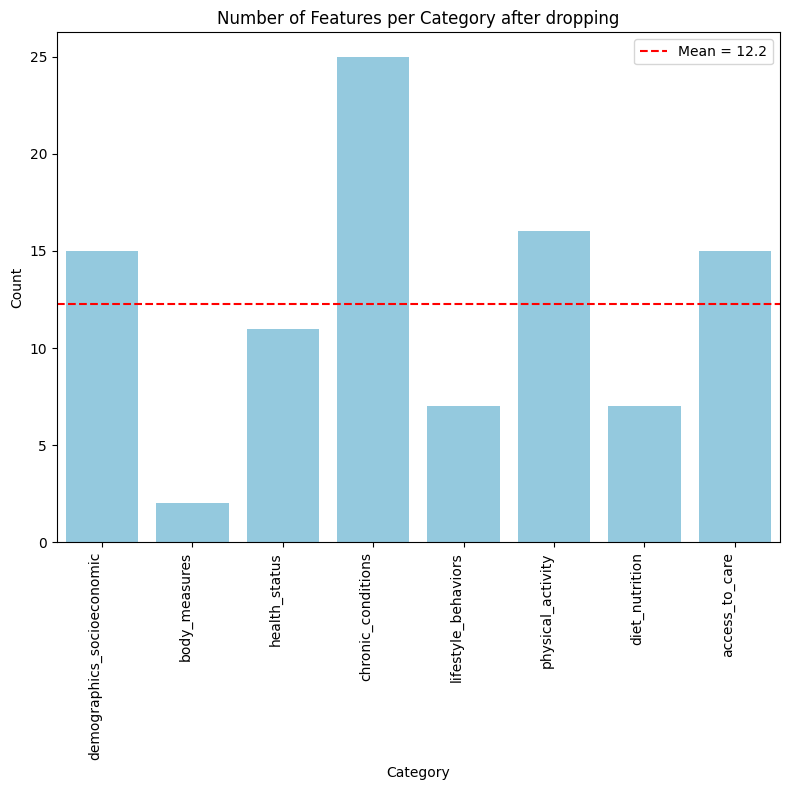

In [ ]:
# number of features per category
category_counts = {cat: len(features) for cat, features in feature_clusters.items()}
cats = list(category_counts.keys())
counts = list(category_counts.values())
plot_path = os.path.join(plots_categories_dir, "features_per_category_after_dropping.png")

mean_val = np.mean(counts)
plt.figure(figsize=(8, 8))
sns.barplot(x=cats, y=counts, color="skyblue")
plt.axhline(mean_val, color="red", linestyle="--", label=f"Mean = {mean_val:.1f}")
plt.title("Number of Features per Category after dropping")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=90, ha="right")
plt.legend()
plt.tight_layout()
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

## Missing vals

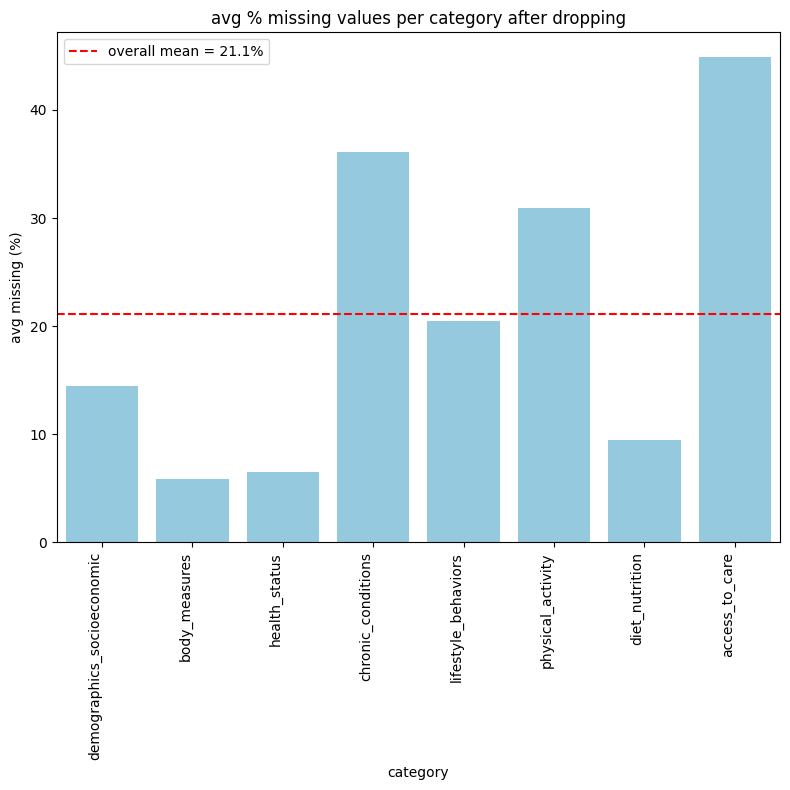

In [ ]:
# % missing per var (reduced set)
missing_perc = np.mean(np.isnan(x_train), axis=0) * 100  
feature_to_cat = {f: c for c, feats in feature_clusters.items() for f in feats}

# group by category and avg
cat_missing = {
    c: np.mean([missing_perc[x_indices_final[f]] for f in feats if f in x_indices_final])
    for c, feats in feature_clusters.items()
}

cats = list(cat_missing.keys())
avg_missing = list(cat_missing.values())


plt.figure(figsize=(8, 8))
sns.barplot(x=cats, y=avg_missing, color="skyblue")
plt.axhline(np.mean(avg_missing), color="red", ls="--",
            label=f"overall mean = {np.mean(avg_missing):.1f}%")
plt.title("avg % missing values per category after dropping")
plt.xlabel("category")
plt.ylabel("avg missing (%)")
plt.xticks(rotation=90, ha="right")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "categories", "missing_values_per_category_after_dropping.png"),
            dpi=300, bbox_inches="tight")
plt.show()


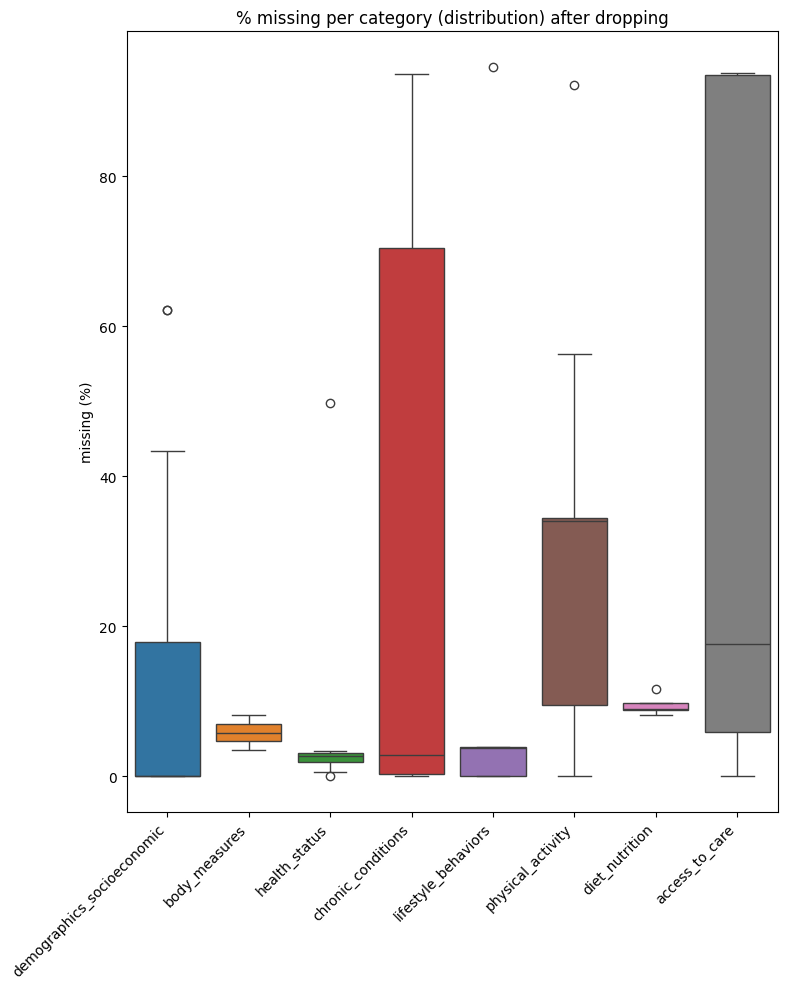

In [ ]:
# boxplot of missing distrib per category
data_box = []
for c, feats in feature_clusters.items():
    vals = [missing_perc[x_indices_final[f]] for f in feats if f in x_indices_final]
    data_box.append(vals)

plt.figure(figsize=(8, 10))
sns.boxplot(data=data_box)
plt.xticks(ticks=range(len(cats)), labels=cats, rotation=45, ha="right")
plt.ylabel("missing (%)")
plt.title("% missing per category (distribution) after dropping")
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "categories", "missing_values_box_after_dropping.png"),
            dpi=300, bbox_inches="tight")
plt.show()


Missing value statistics per category after dropping

demographics_socioeconomic  mean=14.43%  std=23.57%  min= 0.00%  max=62.17%  median= 0.00%  iqr=17.86%  >50%=2
body_measures              mean= 5.86%  std= 2.39%  min= 3.46%  max= 8.25%  median= 5.86%  iqr= 2.39%  >50%=0
health_status              mean= 6.54%  std=13.72%  min= 0.00%  max=49.80%  median= 2.79%  iqr= 1.18%  >50%=0
chronic_conditions         mean=36.12%  std=39.95%  min= 0.00%  max=93.64%  median= 2.89%  iqr=70.12%  >50%=11
lifestyle_behaviors        mean=20.46%  std=37.10%  min= 0.00%  max=94.58%  median= 3.79%  iqr= 3.95%  >50%=1
physical_activity          mean=30.90%  std=23.58%  min= 0.00%  max=92.13%  median=33.99%  iqr=24.90%  >50%=3
diet_nutrition             mean= 9.49%  std= 1.20%  min= 8.21%  max=11.67%  median= 8.95%  iqr= 0.96%  >50%=0
access_to_care             mean=44.94%  std=41.65%  min= 0.00%  max=93.82%  median=17.66%  iqr=87.54%  >50%=7


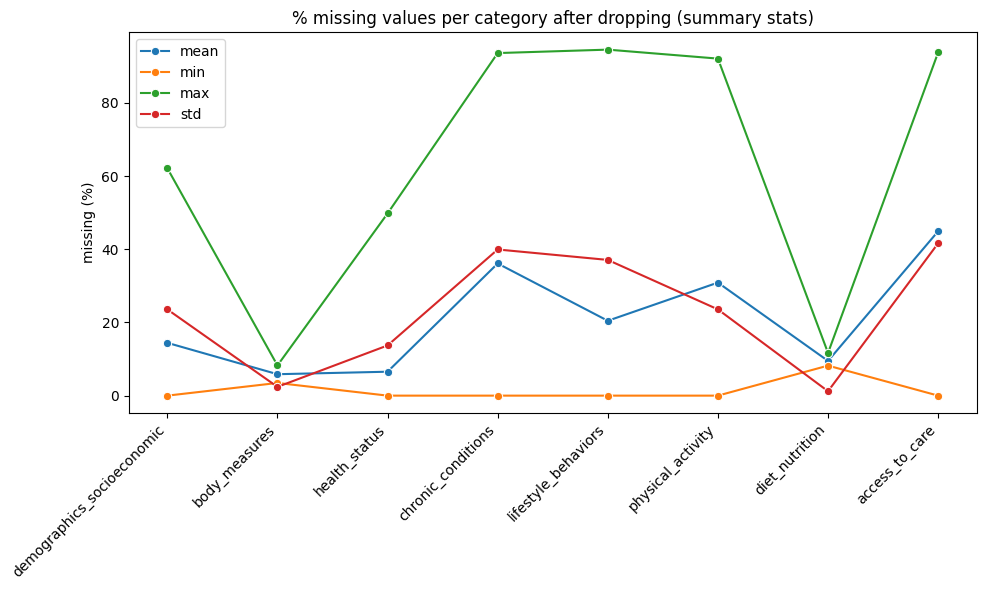

In [ ]:
# % missing per feature
missing_perc = np.mean(np.isnan(x_train), axis=0) * 100

# compute stats per category
cat_names, mean_vals, std_vals, min_vals, max_vals = [], [], [], [], []
med_vals, iqr_vals, count_above_50 = [], [], []

for c, feats in feature_clusters.items():
    vals = [missing_perc[x_indices_final[f]] for f in feats if f in x_indices_final]
    if len(vals) == 0:
        continue
    vals = np.array(vals)
    cat_names.append(c)
    mean_vals.append(np.mean(vals))
    std_vals.append(np.std(vals))
    min_vals.append(np.min(vals))
    max_vals.append(np.max(vals))
    med_vals.append(np.median(vals))
    iqr_vals.append(np.percentile(vals, 75) - np.percentile(vals, 25))
    count_above_50.append(np.sum(vals > 50))

print("\nMissing value statistics per category after dropping\n")
for i, c in enumerate(cat_names):
    print(f"{c:25s}  mean={mean_vals[i]:5.2f}%  std={std_vals[i]:5.2f}%  "
          f"min={min_vals[i]:5.2f}%  max={max_vals[i]:5.2f}%  "
          f"median={med_vals[i]:5.2f}%  iqr={iqr_vals[i]:5.2f}%  "
          f">50%={int(count_above_50[i])}")

# plot mean/min/max/std
plt.figure(figsize=(10, 6))
sns.lineplot(x=cat_names, y=mean_vals, marker="o", label="mean")
sns.lineplot(x=cat_names, y=min_vals, marker="o", label="min")
sns.lineplot(x=cat_names, y=max_vals, marker="o", label="max")
sns.lineplot(x=cat_names, y=std_vals, marker="o", label="std")
plt.xticks(rotation=45, ha="right")
plt.ylabel("missing (%)")
plt.title("% missing values per category after dropping (summary stats)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "categories", "missing_values_after_dropping_summary.png"),
            dpi=300, bbox_inches="tight")
plt.show()


## Inter-category correlation

In [ ]:
len(feature_clusters)

8

### Plots

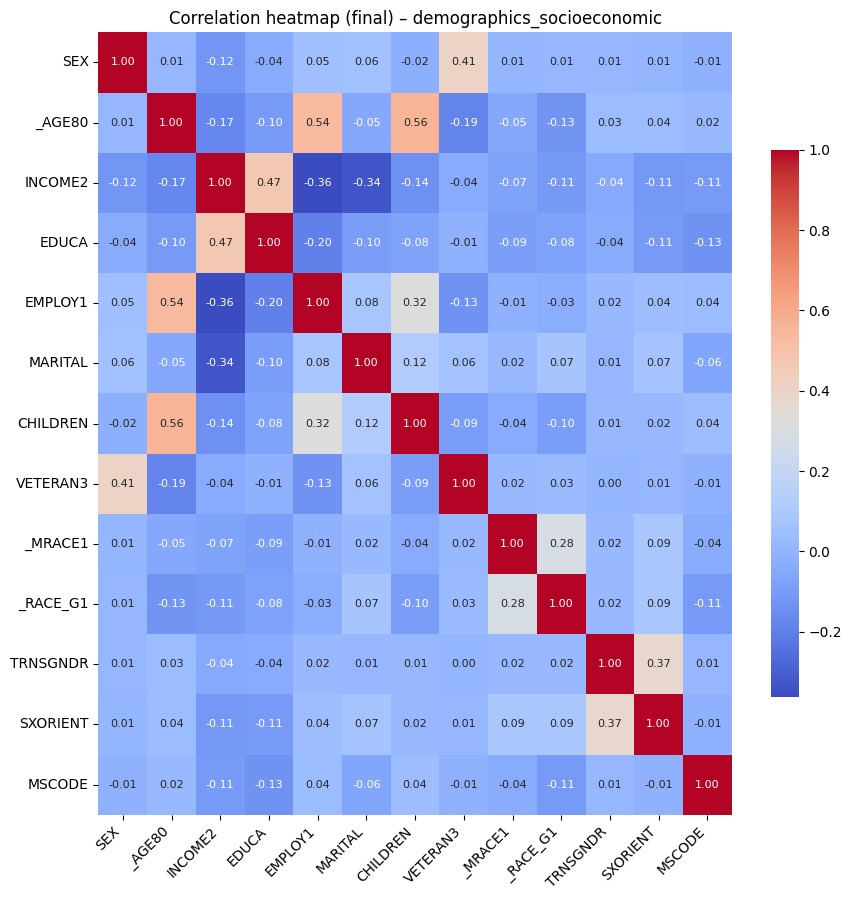

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr_after_final\corr_final_demographics_socioeconomic.png


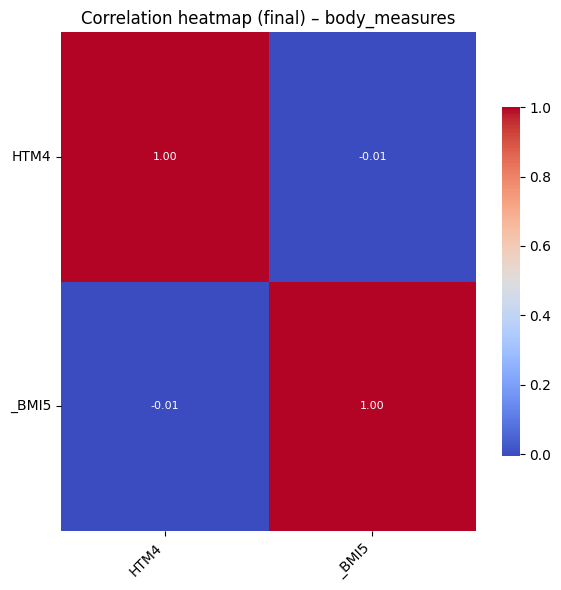

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr_after_final\corr_final_body_measures.png


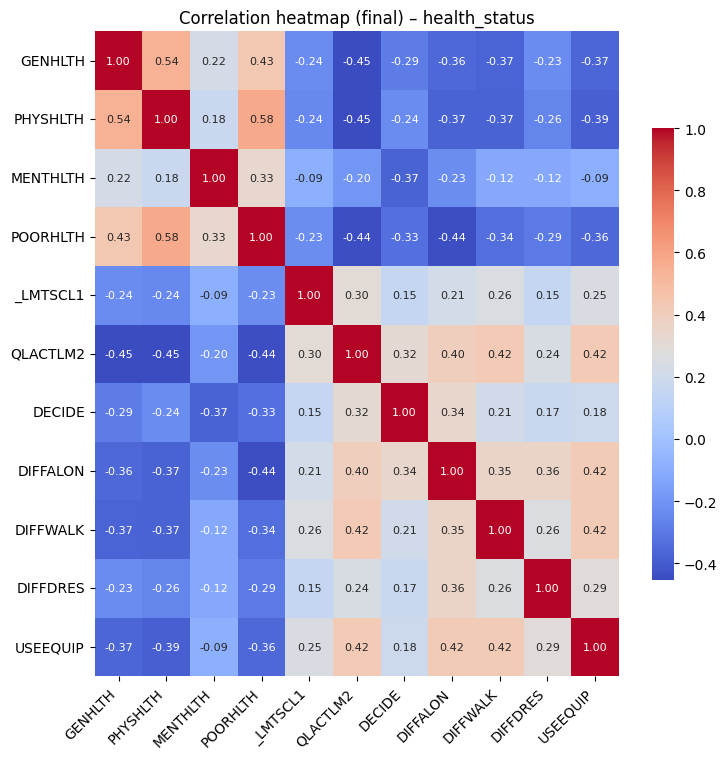

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr_after_final\corr_final_health_status.png


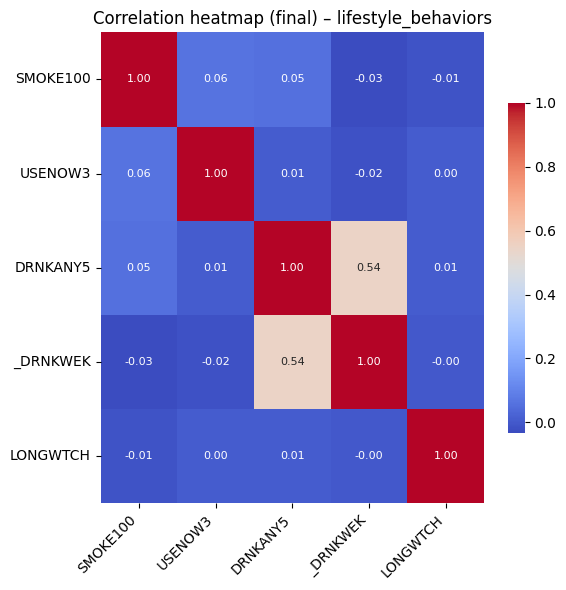

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr_after_final\corr_final_lifestyle_behaviors.png


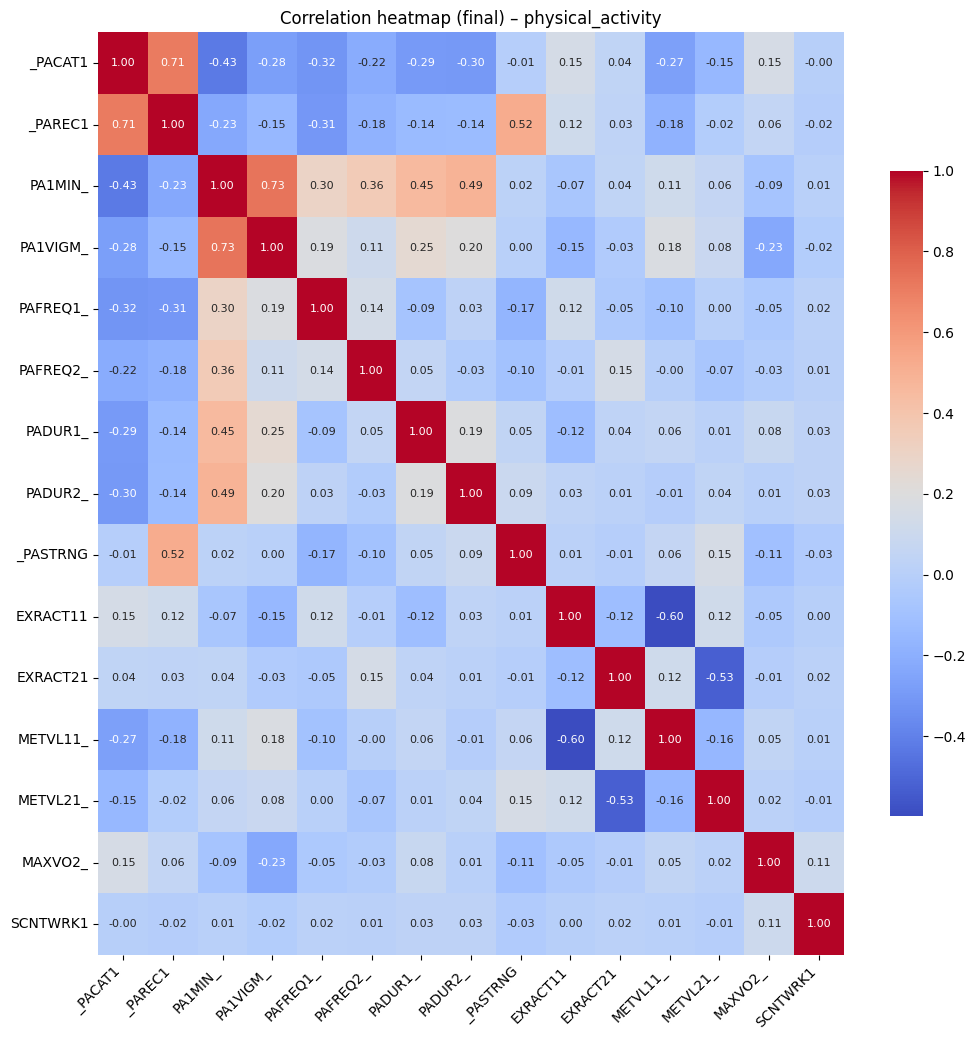

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr_after_final\corr_final_physical_activity.png


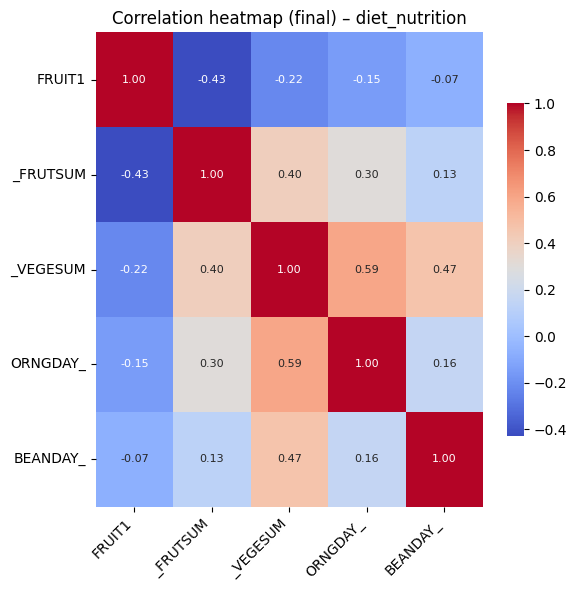

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr_after_final\corr_final_diet_nutrition.png


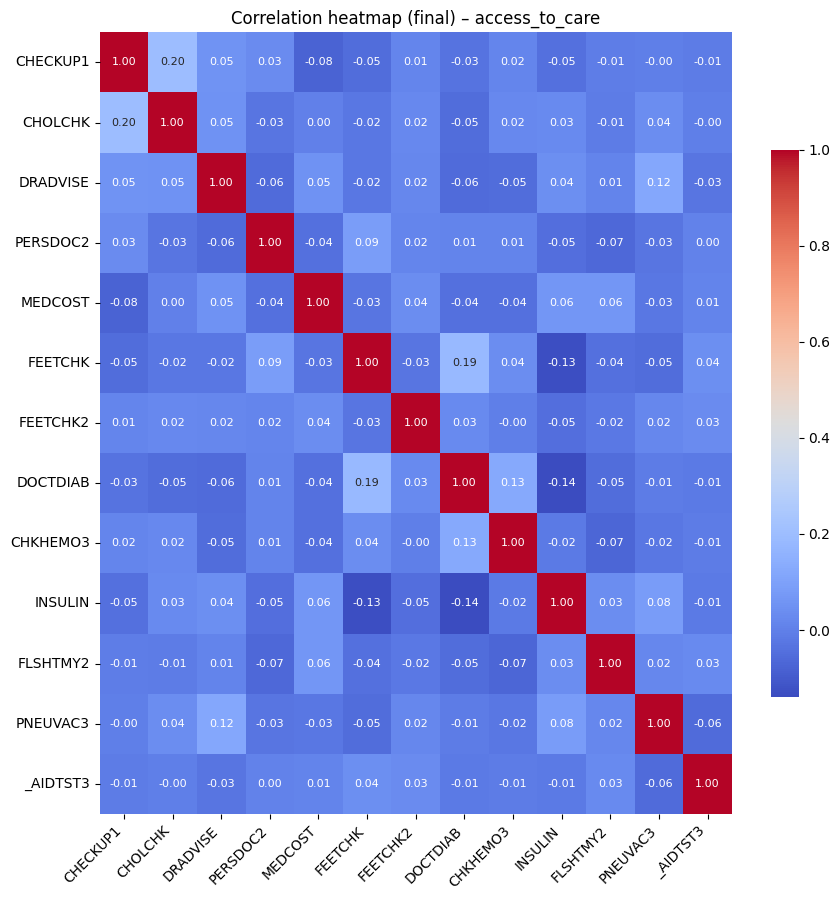

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr_after_final\corr_final_access_to_care.png


In [ ]:
# folder for saving (reuse existing structure)
cat_corr_dir = os.path.join(plots_dir, "categories", "corr_after_final")
os.makedirs(cat_corr_dir, exist_ok=True)

# loop over categories
for c, feats in feature_clusters.items():
    # get indices for existing features in this category
    idxs = [x_indices_final[f] for f in feats if f in x_indices_final]
    if len(idxs) < 2:
        continue  # skip single-feature categories

    # subset data
    data_cat = x_train[:, idxs]

    # drop rows with any NaN values in this category
    mask = ~np.isnan(data_cat).any(axis=1)
    data_clean = data_cat[mask]

    # skip if too few valid rows
    if data_clean.shape[0] < 5:
        continue

    # drop constant columns (avoid zero std)
    stds = np.nanstd(data_clean, axis=0)
    valid_cols = stds > 0
    data_valid = data_clean[:, valid_cols]
    feats_valid = [f for f, keep in zip(feats, valid_cols) if keep]

    if data_valid.shape[1] < 2:
        print(f"Skipping {c}: not enough non-constant features.")
        continue

    # compute correlation
    corr = np.corrcoef(data_valid, rowvar=False)

    # handle uniform values
    vmin, vmax = np.nanmin(corr), np.nanmax(corr)
    if vmin == vmax:
        vmin, vmax = -1, 1

    # plot size (scale with number of features)
    n = len(feats_valid)
    fig_size = max(6, 0.7 * n)
    plt.figure(figsize=(fig_size, fig_size))

    # heatmap with annotations
    sns.heatmap(
        corr,
        vmin=vmin, vmax=vmax,
        cmap="coolwarm",
        annot=True, fmt=".2f", annot_kws={"size": 8},
        xticklabels=feats_valid, yticklabels=feats_valid,
        cbar_kws={"shrink": 0.7}
    )
    plt.title(f"Correlation heatmap (final) – {c}")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()

    # save + show
    save_path = os.path.join(cat_corr_dir, f"corr_final_{c}.png")
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Saved: {save_path}")

## Feature-target correlations

In [ ]:
plots_target_dir = os.path.join(plots_dir, "target_correlations")
os.makedirs(plots_target_dir, exist_ok=True)

plots_summary_dir = os.path.join(plots_dir, "categories", "category_strength")
os.makedirs(plots_summary_dir, exist_ok=True)

print(f"Target correlation plots -> {plots_target_dir}")
print(f"Category summaries -> {plots_summary_dir}")

Target correlation plots -> c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\target_correlations
Category summaries -> c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\category_strength


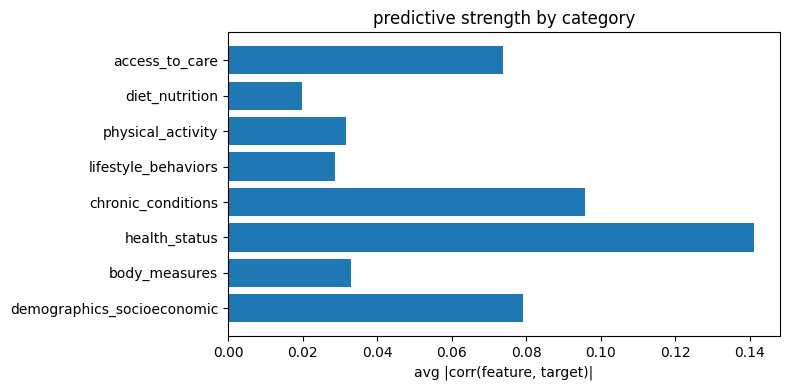

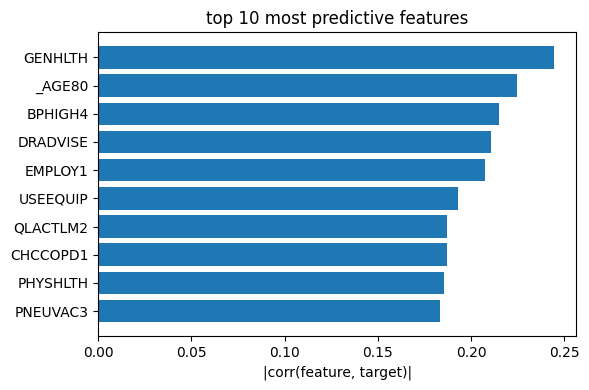

In [ ]:
# make sure y is 1d (ignore id column)
y = y_data[:, 1].astype(float)

# sanity checks
assert y.ndim == 1 and len(y) == x_train.shape[0], "y has wrong shape"
assert set(np.unique(y)) <= {-1, 1}, "unexpected label values"

# compute feature–target correlations
target_corr = {}
for feat_idx, feat_name in enumerate(final_feature_set):
    x = x_train[:, feat_idx]
    mask = ~np.isnan(x)
    if np.sum(mask) > 5:
        corr = np.corrcoef(x[mask], y[mask])[0, 1]
    else:
        corr = np.nan
    target_corr[feat_name] = corr

# avg abs corr per category
cat_corr_summary = {}
for cat, feats in feature_clusters.items():
    vals = [abs(target_corr[f]) for f in feats if f in target_corr and not np.isnan(target_corr[f])]
    if len(vals) > 0:
        cat_corr_summary[cat] = {
            "mean_abs_corr": np.mean(vals),
            "max_abs_corr": np.max(vals),
            "num_features": len(vals)
        }

# plot avg |corr| per category
cats, avg_corrs = zip(*[(k, v["mean_abs_corr"]) for k, v in cat_corr_summary.items()])
plt.figure(figsize=(8, 4))
plt.barh(cats, avg_corrs)
plt.xlabel("avg |corr(feature, target)|")
plt.title("predictive strength by category")
plt.tight_layout()
plt.savefig(os.path.join(plots_summary_dir, "category_avg_target_corr.png"), dpi=300)
plt.show()

# plot top 10 most predictive features
sorted_feats = sorted(target_corr.items(), key=lambda x: abs(x[1]) if not np.isnan(x[1]) else 0, reverse=True)
top10 = sorted_feats[:10]
plt.figure(figsize=(6, 4))
plt.barh([f[0] for f in top10][::-1], [abs(f[1]) for f in top10][::-1])
plt.xlabel("|corr(feature, target)|")
plt.title("top 10 most predictive features")
plt.tight_layout()
plt.savefig(os.path.join(plots_target_dir, "top10_target_corr.png"), dpi=300)
plt.show()

## Variance structure within-category (PCA / eigenvalue check)

In this step, I examine how much independent variation remains inside each feature category using PCA (via SVD).  
Each category is standardized (mean 0, std 1), and I compute:

- the variance explained by each principal component (shown as a bar plot)  
- the cumulative variance explained (scree plot)  
- how many components are needed to reach 95% of the total variance    

Finally, I print a compact summary of all categories and create an overall bar chart  
showing the variance explained by the **first principal component** across categories.

In [ ]:
# make dirs for pca results
plots_pca_dir = os.path.join(plots_categories_dir, "pca")
os.makedirs(plots_pca_dir, exist_ok=True)

results_pca_dir = os.path.join(save_dir, "categories")
os.makedirs(results_pca_dir, exist_ok=True)
pca_csv_path = os.path.join(results_pca_dir, "pca_variance.csv")

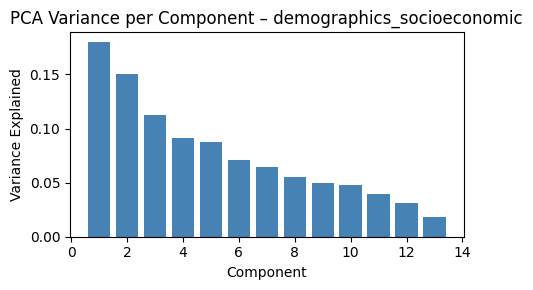

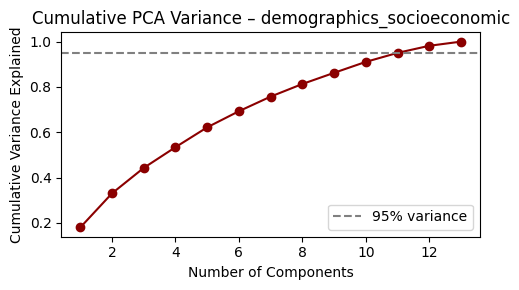

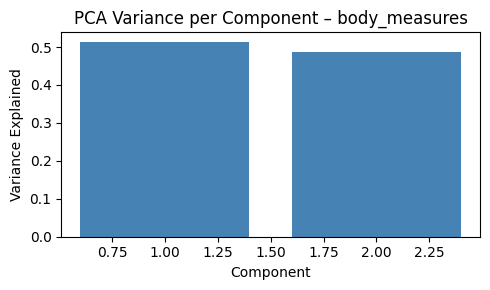

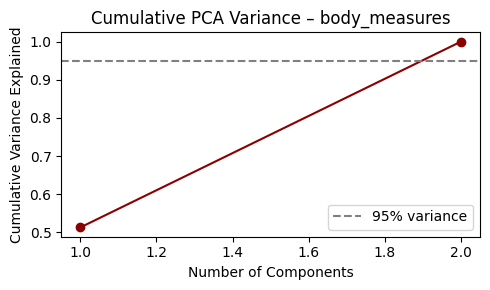

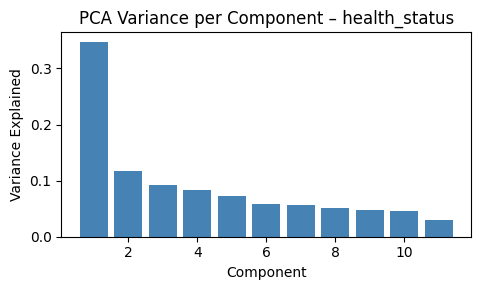

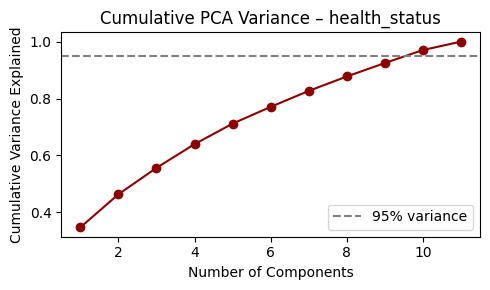

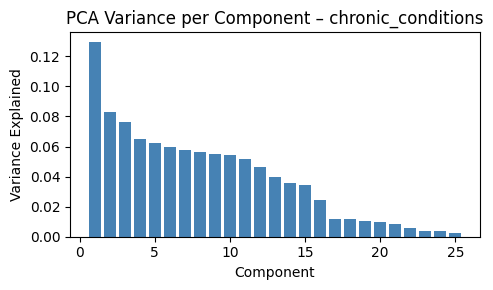

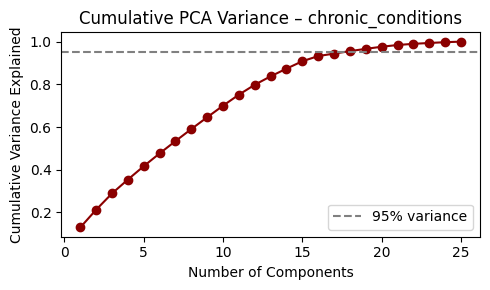

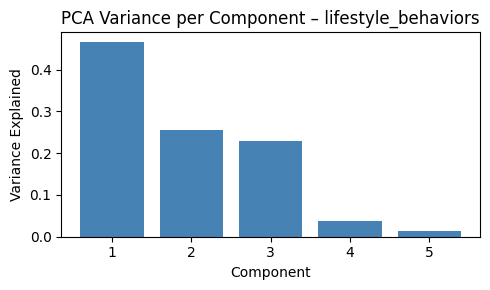

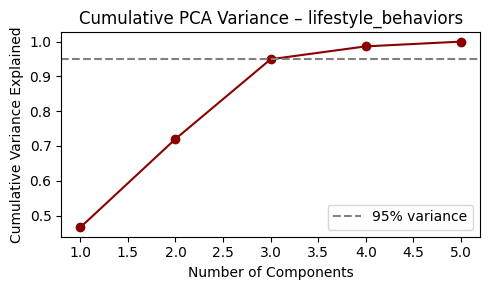

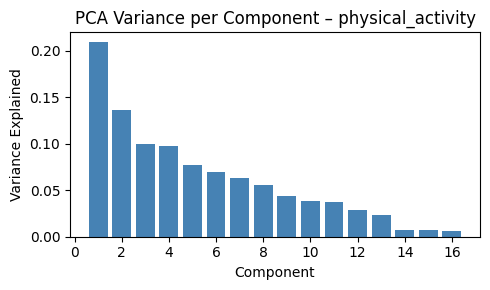

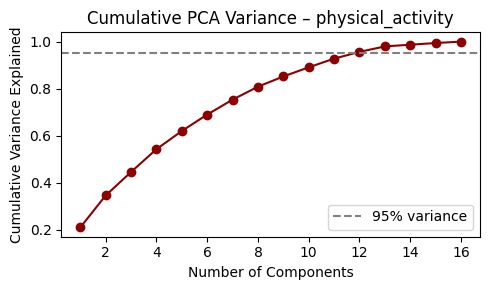

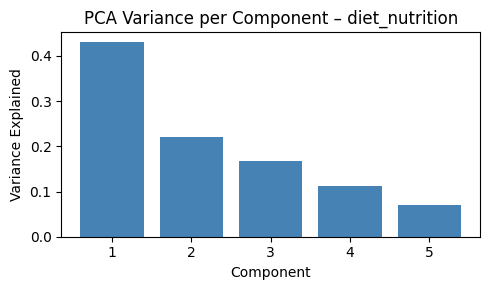

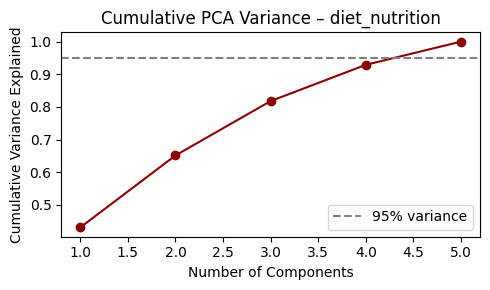

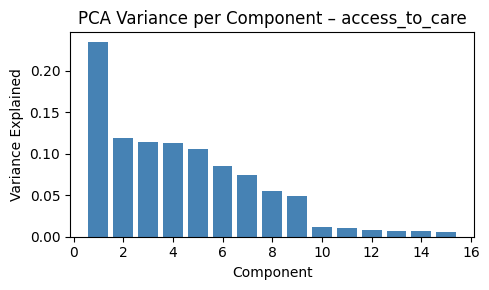

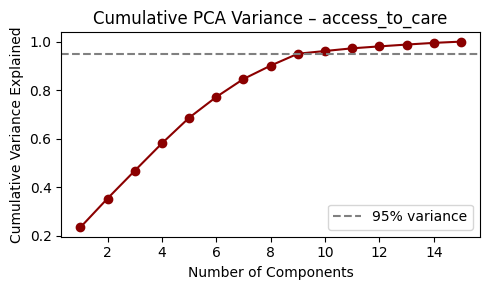


PCA summary by category:

demographics_socioeconomic | features=13 | comps_95=11 | var_first=0.18
body_measures             | features= 2 | comps_95= 2 | var_first=0.51
health_status             | features=11 | comps_95=10 | var_first=0.35
chronic_conditions        | features=25 | comps_95=18 | var_first=0.13
lifestyle_behaviors       | features= 5 | comps_95= 4 | var_first=0.47
physical_activity         | features=16 | comps_95=12 | var_first=0.21
diet_nutrition            | features= 5 | comps_95= 5 | var_first=0.43
access_to_care            | features=15 | comps_95= 9 | var_first=0.23

Saved PCA variance summary: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\results\eda\categories\pca_variance.csv


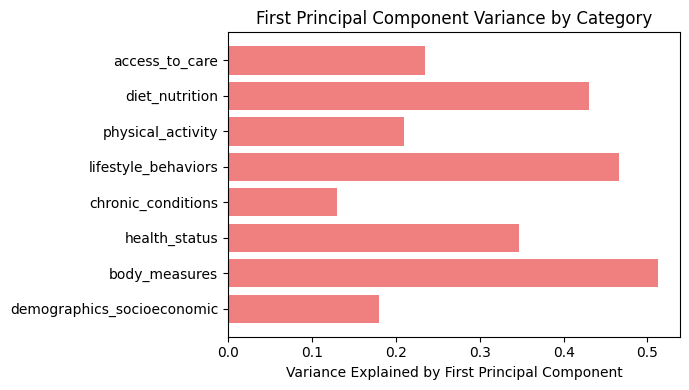

Saved overall PCA summary plot: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\pca\pca_first_component_summary.png


In [ ]:
# helper to compute explained variance from svd
def pca_variance(X):
    # standardize
    X_std = (X - np.nanmean(X, axis=0)) / np.nanstd(X, axis=0)
    X_std = np.nan_to_num(X_std, nan=0.0)
    # svd
    U, S, Vt = np.linalg.svd(X_std, full_matrices=False)
    var_ratio = (S**2) / np.sum(S**2)
    cum_ratio = np.cumsum(var_ratio)
    return var_ratio, cum_ratio


# store results
pca_summary = []

for cat, feats in feature_clusters.items():
    # pick valid cols
    idxs = [final_feature_set.index(f) for f in feats if f in final_feature_set]
    if len(idxs) == 0:
        continue

    X_cat = x_train[:, idxs]
    if np.all(np.isnan(X_cat)):
        print(f"skip {cat}: all NaNs")
        continue

    var_ratio, cum_ratio = pca_variance(X_cat)
    n_comp_95 = np.argmax(cum_ratio >= 0.95) + 1

    # save summary info
    pca_summary.append({
        "category": cat,
        "n_features": len(idxs),
        "n_components_95": n_comp_95,
        "var_first": var_ratio[0],
        "cum_var_95": cum_ratio[n_comp_95 - 1]
    })

    # plot 1: variance explained per component
    plt.figure(figsize=(5, 3))
    plt.bar(np.arange(1, len(var_ratio) + 1), var_ratio, color="steelblue")
    plt.xlabel("Component")
    plt.ylabel("Variance Explained")
    plt.title(f"PCA Variance per Component – {cat}")
    plt.tight_layout()
    save_path_bar = os.path.join(plots_pca_dir, f"pca_var_{cat}.png")
    plt.savefig(save_path_bar, dpi=300)
    plt.show()

    # plot 2: cumulative variance
    plt.figure(figsize=(5, 3))
    plt.plot(np.arange(1, len(cum_ratio) + 1), cum_ratio, marker="o", color="darkred")
    plt.axhline(0.95, color="gray", linestyle="--", label="95% variance")
    plt.xlabel("Number of Components")
    plt.ylabel("Cumulative Variance Explained")
    plt.title(f"Cumulative PCA Variance – {cat}")
    plt.legend()
    plt.tight_layout()
    save_path_cum = os.path.join(plots_pca_dir, f"pca_cum_{cat}.png")
    plt.savefig(save_path_cum, dpi=300)
    plt.show()


# print summary info for all categories
print("\nPCA summary by category:\n")
for row in pca_summary:
    print(f"{row['category']:25s} | features={row['n_features']:2d} | comps_95={row['n_components_95']:2d} | var_first={row['var_first']:.2f}")

# write csv summary
with open(pca_csv_path, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(pca_summary[0].keys()))
    writer.writeheader()
    writer.writerows(pca_summary)

print(f"\nSaved PCA variance summary: {pca_csv_path}")

# plot summary: variance explained by first PC for all categories
cats = [row["category"] for row in pca_summary]
first_var = [row["var_first"] for row in pca_summary]
plt.figure(figsize=(7, 4))
plt.barh(cats, first_var, color="lightcoral")
plt.xlabel("Variance Explained by First Principal Component")
plt.title("First Principal Component Variance by Category")
plt.tight_layout()
save_path_summary = os.path.join(plots_pca_dir, "pca_first_component_summary.png")
plt.savefig(save_path_summary, dpi=300)
plt.show()
print(f"Saved overall PCA summary plot: {save_path_summary}")


### PCA results – takeaways

The PCA results show how much internal redundancy remains inside each category after dropping highly correlated features.

- **demographics_socioeconomic (13 feats, 11 comps for 95%)** → still quite high dimensional. each variable adds its own info (e.g. age, income, education, marital status). low first-component variance (0.18) means no single strong latent factor.  
- **body_measures (2 feats, 2 comps, var_first=0.51)** → expected: height and bmi only moderately related, both needed to capture variance.  
- **health_status (11 feats, 10 comps, var_first=0.35)** → also fairly independent indicators (physical and mental health, limitations, etc.).  
- **chronic_conditions (25 feats, 18 comps, var_first=0.13)** → very high dimensional; diseases behave mostly independently, so compression would lose info.  
- **lifestyle_behaviors (5 feats, 4 comps, var_first=0.47)** → some overlap (e.g. smoking/drinking), but overall still diverse.  
- **physical_activity (16 feats, 12 comps, var_first=0.21)** → moderate redundancy, makes sense since many variables describe related activity levels.  
- **diet_nutrition (5 feats, 5 comps, var_first=0.43)** → relatively independent diet metrics.  
- **access_to_care (15 feats, 9 comps, var_first=0.23)** → moderate overlap between health check and vaccination features.

In short, most categories remain quite rich and not strongly compressible - suggesting that the reduced feature set still captures multiple independent aspects of health behavior and status.


## Cross-category correlations

In [ ]:
# make dirs for plots and results
plots_corr_dir = os.path.join(plots_categories_dir, "corr")
os.makedirs(plots_corr_dir, exist_ok=True)

results_corr_dir = os.path.join(save_dir, "categories", "corr")
os.makedirs(results_corr_dir, exist_ok=True)

C:\Users\emmaa\AppData\Local\Temp\ipykernel_21356\2196759682.py:8: RuntimeWarning: Mean of empty slice
  cat_means[cat] = np.nanmean(X_cat, axis=1)


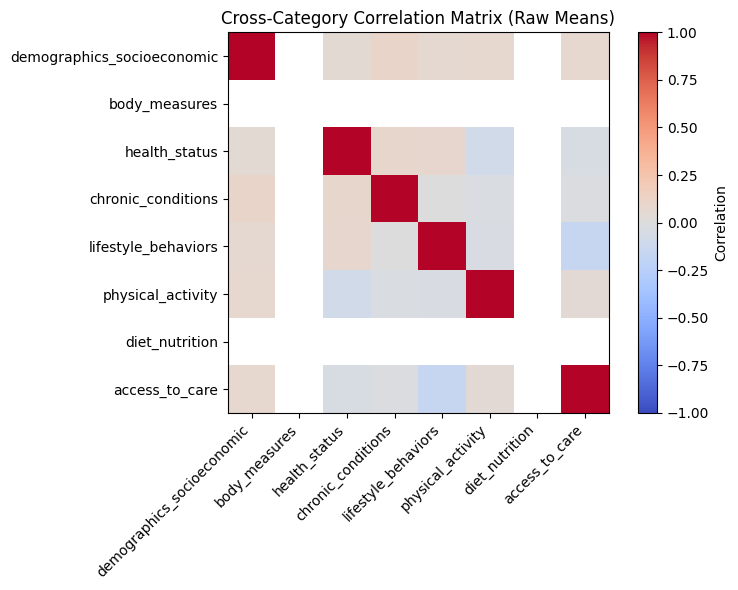

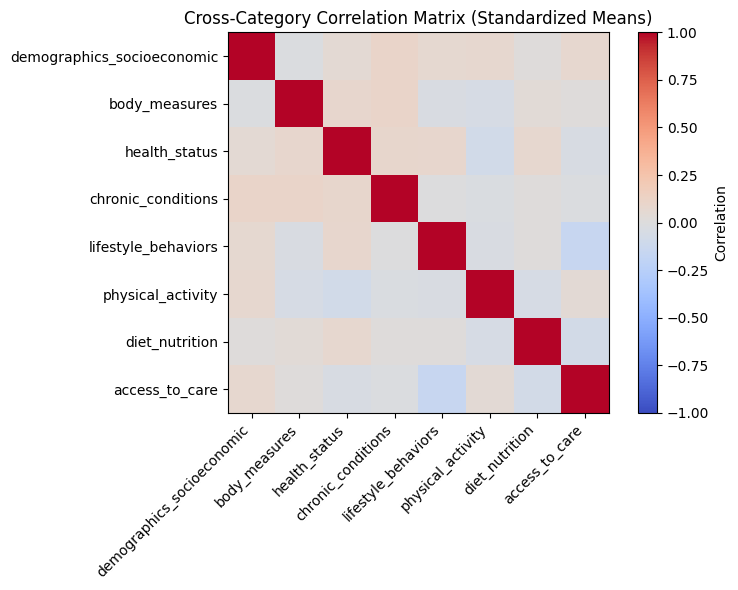


=== Cross-category correlations (standardized means) ===

lifestyle_behaviors       <--> access_to_care             r=-0.155
demographics_socioeconomic <--> chronic_conditions         r=+0.104
body_measures             <--> chronic_conditions         r=+0.102
health_status             <--> chronic_conditions         r=+0.094
health_status             <--> physical_activity          r=-0.085
health_status             <--> lifestyle_behaviors        r=+0.083
body_measures             <--> health_status              r=+0.080
demographics_socioeconomic <--> physical_activity          r=+0.078
demographics_socioeconomic <--> access_to_care             r=+0.078
health_status             <--> diet_nutrition             r=+0.075
diet_nutrition            <--> access_to_care             r=-0.072
demographics_socioeconomic <--> lifestyle_behaviors        r=+0.067
physical_activity         <--> diet_nutrition             r=-0.053
body_measures             <--> physical_activity          r=-0.051

In [ ]:
# compute mean value per category for each sample
cat_means = {}
for cat, feats in feature_clusters.items():
    idxs = [final_feature_set.index(f) for f in feats if f in final_feature_set]
    if len(idxs) == 0:
        continue
    X_cat = x_train[:, idxs]
    cat_means[cat] = np.nanmean(X_cat, axis=1)

# build matrix of category means
cat_names = list(cat_means.keys())
cat_matrix = np.vstack([cat_means[c] for c in cat_names]).T

# compute correlation matrix (raw)
corr_mat = np.corrcoef(cat_matrix, rowvar=False)
np.save(os.path.join(results_corr_dir, "inter_category_corr_raw.npy"), corr_mat)

# plot raw correlation heatmap
plt.figure(figsize=(8, 6))
plt.imshow(corr_mat, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(cat_names)), cat_names, rotation=45, ha="right")
plt.yticks(range(len(cat_names)), cat_names)
plt.title("Cross-Category Correlation Matrix (Raw Means)")
plt.tight_layout()
save_path_raw = os.path.join(plots_corr_dir, "inter_category_corr_raw.png")
plt.savefig(save_path_raw, dpi=300)
plt.show()

# standardize category means before correlation (fix for NaNs)
cat_matrix_std = (cat_matrix - np.nanmean(cat_matrix, axis=0)) / np.nanstd(cat_matrix, axis=0)
cat_matrix_std = np.nan_to_num(cat_matrix_std, nan=0.0)

# recompute correlation matrix on standardized data
corr_mat_std = np.corrcoef(cat_matrix_std, rowvar=False)
np.save(os.path.join(results_corr_dir, "inter_category_corr_standardized.npy"), corr_mat_std)

# plot standardized correlation heatmap
plt.figure(figsize=(8, 6))
plt.imshow(corr_mat_std, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(cat_names)), cat_names, rotation=45, ha="right")
plt.yticks(range(len(cat_names)), cat_names)
plt.title("Cross-Category Correlation Matrix (Standardized Means)")
plt.tight_layout()
save_path_std = os.path.join(plots_corr_dir, "inter_category_corr_standardized.png")
plt.savefig(save_path_std, dpi=300)
plt.show()

# print sorted pairwise correlations (standardized)
pairs = []
n = len(cat_names)
for i in range(n):
    for j in range(i + 1, n):
        r = corr_mat_std[i, j]
        if not np.isnan(r):
            pairs.append((cat_names[i], cat_names[j], r))

# sort by absolute correlation, descending
pairs_sorted = sorted(pairs, key=lambda x: abs(x[2]), reverse=True)

print("\n=== Cross-category correlations (standardized means) ===\n")
for a, b, r in pairs_sorted:
    print(f"{a:25s} <--> {b:25s}  r={r:+.3f}")

# save printed correlations to file
corr_txt_path = os.path.join(results_corr_dir, "inter_category_corr_pairs.txt")
with open(corr_txt_path, "w") as f:
    for a, b, r in pairs_sorted:
        f.write(f"{a:25s} <--> {b:25s}  r={r:+.3f}\n")

After standardizing category-level means, correlations between feature categories are generally weak (|r| < 0.2), which suggests that the main health domains are largely independent - a good sign, since it means the categories capture distinct aspects of the data rather than overlapping information.

A few small trends appear:

- **Lifestyle behaviors ↔ Access to care (r = –0.16)**: Individuals with riskier behaviors may engage less with healthcare systems or preventive services.
- **Demographics & socioeconomic ↔ Chronic conditions (r = +0.10)**: Slight positive link, consistent with age and income effects on chronic disease prevalence.
- **Body measures ↔ Chronic conditions (r = +0.10)** and **Health status ↔ Chronic conditions (r = +0.09)**: Expected mild associations, since BMI and self-reported health often relate to chronic illness.
- **Health status ↔ Physical activity (r = –0.09)**: Individuals reporting worse health may be less active.

Overall, no strong inter-category dependencies remain - confirming that the **final reduced feature set is well-balanced and non-redundant** across domains.